__aims__: 
- Use these V2 screens for ScreenPro2 DevOps

__tasks__: 
- [ ] compare ScreenProcessing guide level scores with ScreenPro2 scores.

In [5]:
# !pip uninstall -y screenpro2
!pip install git+https://github.com/ArcInstitute/ScreenPro2.git@abearab/issue17

  Cloning https://github.com/ArcInstitute/ScreenPro2.git (to revision abearab/issue17) to /var/tmp/pip-req-build-21max9tm
  Running command git clone --filter=blob:none --quiet https://github.com/ArcInstitute/ScreenPro2.git /var/tmp/pip-req-build-21max9tm
  Running command git checkout -b abearab/issue17 --track origin/abearab/issue17
  Switched to a new branch 'abearab/issue17'
  Branch 'abearab/issue17' set up to track remote branch 'abearab/issue17' from 'origin'.
  Resolved https://github.com/ArcInstitute/ScreenPro2.git to commit 2cc5612baa6721b94baf9ec6fa38948fe15f36bc
  Preparing metadata (setup.py) ... done
  Created wheel for ScreenPro2: filename=ScreenPro2-0.2.6-py3-none-any.whl size=15128 sha256=34c43ea8172d88a0abaa9cd1f7c518da8abda36b036c7cac54df73b83681fec4
  Stored in directory: /var/tmp/pip-ephem-wheel-cache-r28_plj0/wheels/e3/37/bb/7658418def8096dd9c6dc189c38cf03818d43cbacb164fdb64
Successfully built ScreenPro2


In [6]:
import pandas as pd
import anndata as ad
import screenpro as scp

In [7]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib import rcParams, rc_context

In [8]:
from matplotlib import font_manager as fm

from matplotlib import rcParams, rc_context

font_files = fm.findSystemFonts(fontpaths=None, fontext='ttf')

for font_file in font_files:
    fm.fontManager.addfont(font_file)

# {f.name for f in matplotlib.font_manager.fontManager.ttflist}

rcParams['font.family'] = ['Arial']

In [9]:
import numpy as np

In [10]:
# from plotnine import *

In [11]:
# pagerdir='/data_gilbert/home/aarab/tools/pager'

In [12]:
# msigdb_c5_go_gmt = blitz.enrichr.read_gmt(
#     f'{pagerdir}/annotations/human/msigdb_v7.4_c5.go/c5.go.v7.4.symbols.gmt'
# )

In [13]:
# !pip install blitzgsea

In [14]:
import blitzgsea as blitz

# 
Gather data

In [15]:
# get counts
for exp_id in ['hl60_exp1','skm1_exp','molm13_exp']:
    for table_id in ['phenotypetable','mergedcountstable','genetable_collapsed']:
        !wget -P dac_screens/{exp_id}/ \
            https://raw.githubusercontent.com/GilbertLabUCSF/Decitabine-treatment/main/DAC/CRISPRi-screen/{exp_id}/{table_id}.txt &> /dev/null

In [16]:
# http://humantfs.ccbr.utoronto.ca/download.php
# TF gene names (.txt)
!wget -P ../annotations http://humantfs.ccbr.utoronto.ca/download/v_1.01/TF_names_v_1.01.txt

--2024-02-15 19:31:01--  http://humantfs.ccbr.utoronto.ca/download/v_1.01/TF_names_v_1.01.txt
Resolving humantfs.ccbr.utoronto.ca (humantfs.ccbr.utoronto.ca)... 142.150.52.218
Connecting to humantfs.ccbr.utoronto.ca (humantfs.ccbr.utoronto.ca)|142.150.52.218|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 11838 (12K) [text/plain]
Saving to: ‘../annotations/TF_names_v_1.01.txt.1’

TF_names_v_1.01.txt 100%[===================>]  11.56K  --.-KB/s    in 0.05s   

2024-02-15 19:31:01 (237 KB/s) - ‘../annotations/TF_names_v_1.01.txt.1’ saved [11838/11838]



In [17]:
TFs_list = pd.read_csv('../annotations/TF_names_v_1.01.txt',header=None)[0].to_list()

### Load screen data

In [18]:
screens = {}

for exp in ['hl60_exp1','molm13_exp','skm1_exp']:
    name = exp.split('_')[0]
    cnt = pd.read_csv(f'dac_screens/{exp}/mergedcountstable.txt',sep='\t', header=list(range(2)),index_col=list(range(1)))
    meta = cnt.columns.to_frame().reset_index(drop=True)
    samples = [f'{exp}_sample_{i+1}' for i in meta.index.to_list()]
    cnt.columns = samples
    meta.index = samples
    meta.columns = ['condition','replicate']
    meta.replicate = meta.replicate.str[-1].astype(int)
    
    oligo = cnt.index.to_frame()
    oligo.index.name = None
    oligo['target'] = oligo.sgId.str.split('_').str[0]
    del oligo['sgId']
    oligo['targetType'] = oligo.target.apply(lambda x: "negCtrl" if x == "non-targeting" else "targeting")
    oligo = oligo.sort_values('target').sort_values('targetType',ascending=False)
    oligo.targetType = pd.Categorical(oligo.targetType,categories=['targeting','negCtrl'])
    
    adata = ad.AnnData(X=cnt.loc[oligo.index,:].T.astype(float) + 1, var=oligo, obs=meta)
    scp.ps.seqDepthNormalization(adata)
    
    # adata = 
    scp.utils.find_low_counts(adata)
    
    phenotypetable = pd.read_csv(f'dac_screens/{exp}/phenotypetable.txt',sep='\t',header=[0,1],index_col=0)
    genetable = pd.read_csv(f'dac_screens/{exp}/genetable_collapsed.txt',sep='\t',header=[0,1,2],index_col=0)
    
    screens[name] = scp.ScreenPro(adata)
    screens[name].phenotypes.update({
        'phenotypetable':phenotypetable,
        'genetable':genetable
    })

1849 variables with less than 50 reads in either replicates / experiment
3008 variables with less than 50 reads in either replicates / experiment
1991 variables with less than 50 reads in either replicates / experiment


# 

In [19]:
def plot_scatter_with_annotations(ax, phe, gamma, rho, target_name,exp='',selected_size=30, default_size=3):
    # Scatter plot for targeting data
    targeting_data = phe[phe['targetType'] == 'targeting']
    ax.scatter(targeting_data[gamma], targeting_data[rho],
               s=default_size, linewidth=0.3, edgecolors='black', facecolors='#3182bd', label='Targeting')

    # Scatter plot for non-targeting data
    non_targeting_data = phe[phe['targetType'] == 'negCtrl']
    ax.scatter(non_targeting_data[gamma], non_targeting_data[rho],
               s=default_size, linewidth=0, edgecolors='black', facecolors='gray', label='Non-Targeting')

    # Annotate the specified target name with increased size
    target_row = targeting_data[targeting_data['target'] == target_name]
    ax.scatter(target_row[gamma], target_row[rho],
               s=selected_size, linewidth=0.5, edgecolors='black', facecolors='#d73027', label=target_name)
    # # Annotate the specified target name
    # target_row = targeting_data[targeting_data['target'] == target_name]
    # ax.annotate(target_name, (target_row[gamma].iloc[0], target_row[rho].iloc[0]))

    # Set x-axis and y-axis labels
    ax.set_xlabel(f'{exp} gamma score')
    ax.set_ylabel(f'{exp} rho score')

    # # Add legend
    # ax.legend()

    ax.set_title(target_name)
    
    return ax

### 

In [20]:
screens['hl60']

obs->samples
var->oligos

AnnData object with n_obs × n_vars = 6 × 104535
    obs: 'condition', 'replicate', 'size_factors'
    var: 'target', 'targetType', 'low_count'
    layers: 'seq_depth_norm'

Phenotypes in score_level = 'phenotypetable':
    scores: 'gamma', 'rho', 'tau'
Phenotypes in score_level = 'genetable':
    scores: 'gamma', 'rho', 'tau'

In [21]:
gamma_hl60 = screens['hl60'].phenotypes['phenotypetable']['gamma']#['ave_Rep1_Rep2']

In [22]:
gamma_hl60[gamma_hl60.index.str.contains('METTL14')]

,Rep1,Rep2,ave_Rep1_Rep2
sgId,,,
METTL14_+_119607013.23-P1P2,0.024501,0.027094,0.025797
METTL14_-_119606560.23-P1P2,-0.002057,-0.010708,-0.006382
METTL14_-_119606630.23-P1P2,0.010789,-0.036203,-0.012707
METTL14_-_119606721.23-P1P2,0.004758,0.042077,0.023417
METTL14_-_119606785.23-P1P2,0.009025,0.022760,0.015893


# 

In [23]:
rho_hl60 = screens['hl60'].phenotypes['phenotypetable']['rho']#['ave_Rep1_Rep2']

In [24]:
rho_hl60.loc[rho_hl60.index.str.contains('SPI1'),:]

,Rep1,Rep2,ave_Rep1_Rep2
sgId,,,
SPI1_+_47399936.23-P1P2,0.039316,-0.222827,-0.091755
SPI1_+_47400057.23-P1P2,NaN,NaN,NaN
SPI1_+_47400060.23-P1P2,-0.238292,-0.303112,-0.270702
SPI1_-_47399863.23-P1P2,NaN,NaN,NaN
SPI1_-_47400003.23-P1P2,NaN,NaN,NaN


In [25]:
from screenpro.plotting import almost_black

In [26]:
molm13_db = {
    "DMSO":10.04,
    "DAC":7.46,
}

screens['molm13'].adata.obs['pop_doublings'] = [
    molm13_db['DAC'], molm13_db['DAC'],
    molm13_db['DMSO'], molm13_db['DMSO'],
    np.nan,np.nan
]

In [37]:
growth_factor_table

,score,growth_factor,replicate
0,gamma,10.04,1
1,tau,7.46,1
2,rho,2.58,1
3,gamma,10.04,2
4,tau,7.46,2
5,rho,2.58,2


In [81]:
def plot_score_benchmark(screen, growth_factor_table, score, cond1, cond2, get_z_score, title):
    screenprocessing_results = screen.phenotypes['phenotypetable'][score]

    screenpro2_results = scp.ps.runPhenoScoreForReplicate(
        screen,cond1,cond2,
        score,
        growth_factor_table,
        get_z_score=get_z_score
    ).loc[screenprocessing_results.index,:]#.add_prefix('hl60_gamma_')

    fig, ax = plt.subplots(figsize=(3.7,3.7))

    ax.scatter(
        x=screenprocessing_results['Rep1'],
        y=screenpro2_results['replicate_1'],
        facecolors='#3182bd',
        s=3,c=almost_black
    )
    ax.set_xlabel('ScreenProcessing')
    ax.set_ylabel('ScreenPro2\nscore')

    ax.axline((0, 0), slope=1)

    # ax.set_xlim(-3.5,3.5)
    # ax.set_ylim(-3.5,3.5)

    fig.suptitle(title,fontsize=12)

    # plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
    # plt.tight_layout()
    plt.show()

In [94]:
growth_factor_table = scp.utils.calculateGrowthFactor(
    screens['molm13'], 
    untreated = 'DMSO', treated = 'DAC', 
    db_rate_col = 'pop_doublings'
)

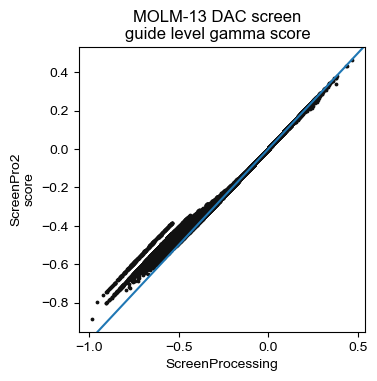

In [95]:
plot_score_benchmark(
    screen = screens['molm13'],
    growth_factor_table = growth_factor_table,
    score = 'gamma',
    cond1 = 'T0',
    cond2 = 'DMSO',
    get_z_score=False,
    title = 'MOLM-13 DAC screen\nguide level gamma score'
)

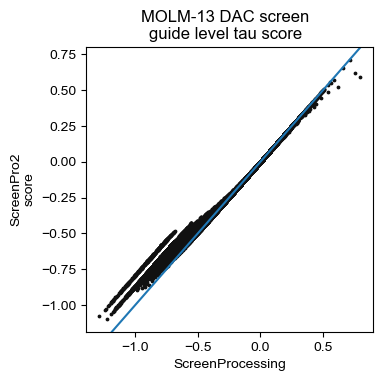

In [96]:
plot_score_benchmark(
    screen = screens['molm13'],
    growth_factor_table = growth_factor_table,
    score = 'tau',
    cond1 = 'T0',
    cond2 = 'DAC',
    get_z_score=False,
    title = 'MOLM-13 DAC screen\nguide level tau score'
)

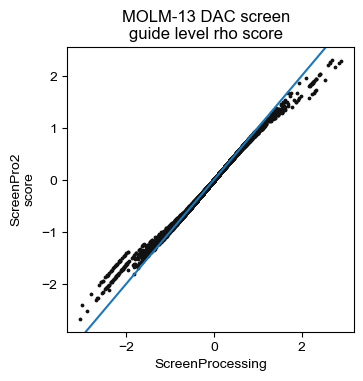

In [97]:
plot_score_benchmark(
    screen = screens['molm13'],
    growth_factor_table = growth_factor_table,
    score = 'rho',
    cond1 = 'DMSO',
    cond2 = 'DAC',
    get_z_score=False,
    title = 'MOLM-13 DAC screen\nguide level rho score'
)

# 

In [ ]:
phe = pd.concat([
    # get_replicate_score(screens['hl60'],'untreated', 'treated',
    #                    molm13_db['untreated'] - molm13_db['treated'],
    #                    ).add_prefix('hl60_rho_'),
    scp.ps.runPhenoScoreForReplicate(screens['hl60'],'T0', 'untreated',
                       molm13_db['untreated']
                       ).add_prefix('hl60_gamma_'),
    scp.ps.runPhenoScoreForReplicate(screens['hl60'],'T0', 'treated',
                       molm13_db['treated'],
                       ).add_prefix('hl60_tau_'),
    
    # get_replicate_score(screens['molm13'],'DMSO', 'DAC',
    #                    molm13_db['untreated'] - molm13_db['treated'],
    #                    ).add_prefix('molm13_rho_'),
    
    scp.ps.runPhenoScoreForReplicate(screens['molm13'],'T0', 'DMSO',
                       molm13_db['untreated'],
                       ).add_prefix('molm13_gamma_'),
    scp.ps.runPhenoScoreForReplicate(screens['molm13'],'T0', 'DAC',
                       molm13_db['treated'],
                       ).add_prefix('molm13_tau_'),

    # get_replicate_score(screens['skm1'],'DMSO', 'DAC',
    #                     molm13_db['untreated'] - molm13_db['treated'],
    #                    ).add_prefix('skm1_rho_'),
    
    scp.ps.runPhenoScoreForReplicate(screens['skm1'],'T0', 'DMSO',
                        molm13_db['untreated']
                       ).add_prefix('skm1_gamma_'),
    scp.ps.runPhenoScoreForReplicate(screens['skm1'],'T0', 'DAC',
                        molm13_db['treated'],
                       ).add_prefix('skm1_tau_'),
],axis=1).T

pdata = ad.AnnData(X=phe,var=oligo)

pdata.obs['cell_line'] = pdata.obs.index.str.split('_').str[0]
pdata.obs['score'] = pdata.obs.index.str.split('_').str[1]
pdata.obs['replicate'] = pdata.obs.index.str.split('_').str[-1]

pdata_filt = pd.concat(dict([(line,screens[line].adata.var['low_count']) for line in screens]),axis=1).sum(axis=1).gt(0)

pdata = pdata[:,~pdata_filt].copy()

In [ ]:
# pdata0 = pdata.copy()

In [ ]:
# pdata = pdata0[pdata0.obs.score.isin(['rho','gamma'])].copy()

### 

In [ ]:
sc.tl.pca(pdata)#, svd_solver='arpack')

In [ ]:
with rc_context({'figure.figsize': (3, 3)}):
    sc.pl.pca_variance_ratio(pdata, n_pcs=8)
    plt.tight_layout()
    plt.show()

In [ ]:
with rc_context({'figure.figsize': (2, 2)}):
    sc.pl.pca_scatter(pdata,color='score',size=300,alpha=0.7)
    sc.pl.pca_scatter(pdata,color='cell_line',size=300,alpha=0.7)

In [ ]:
pca = plot_ggplot_pca(pdata,fill = 'cell_line',shape='score',legend_position=None,figure_size= (6, 3.5))

In [ ]:
pca#.save('pca.pdf')

In [ ]:
from screenpro.plotting import almost_black

In [17]:
def draw_scatter(adata, x, y, title, ax):
    bdata = adata[[x, y],:].copy()
    
    print(bdata.shape)
    
    bdata.obs.index = [f'Replicate {str(r)}' for r in bdata.obs.replicate.to_list()]
    x_lab, y_lab = [f'Replicate {str(r)}' for r in bdata.obs.replicate.to_list()]
    
    sc.pp.log1p(bdata)
    sc.pl.scatter(
        bdata,
        x_lab, y_lab,
        legend_fontsize='xx-large',
        palette=[almost_black,'#BFBFBF'],
        color='targetType',
        title=title,
        size=5,
        show=False,
        ax = ax
    )
    ax.set_ylim(-2,1)
    ax.set_xlim(-2,1)
    ax.tick_params(axis='both', labelsize=10)
    ax.get_legend().remove()
    
    ax.grid(False)

In [ ]:
fig, axes = plt.subplots(ncols=4,
                         figsize=(10,3), 
                         gridspec_kw={'wspace': 0.5, 'left': 0.12,'top':.8,'bottom':.3}, 
                         # sharey=True
                        )

draw_scatter(pdata, 'hl60_gamma_replicate_1','hl60_gamma_replicate_2','hl60_gamma', axes[0])
draw_scatter(pdata, 'hl60_tau_replicate_1','hl60_tau_replicate_2','hl60_tau', axes[1])

draw_scatter(pdata, 'molm13_gamma_replicate_1','molm13_gamma_replicate_2','molm13_gamma', axes[2])
draw_scatter(pdata, 'molm13_tau_replicate_1','molm13_tau_replicate_2','molm13_tau', axes[3])

# fig.suptitle('PRDX1 parent screen',fontsize=15)

# plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
plt.show()

In [ ]:
fig, axes = plt.subplots(ncols=4,
                         figsize=(10,3), 
                         gridspec_kw={'wspace': 0.5, 'left': 0.12,'top':.8,'bottom':.3}, 
                         # sharey=True
                        )
draw_scatter(pdata0, 'hl60_gamma_replicate_1','hl60_gamma_replicate_2','hl60_gamma', axes[0])
draw_scatter(pdata0, 'hl60_tau_replicate_1','hl60_tau_replicate_2','hl60_tau', axes[1])

draw_scatter(pdata0, 'molm13_gamma_replicate_1','molm13_gamma_replicate_2','molm13_gamma', axes[2])
draw_scatter(pdata0, 'molm13_tau_replicate_1','molm13_tau_replicate_2','molm13_tau', axes[3])

# fig.suptitle('PRDX1 parent screen',fontsize=15)

# plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
plt.show()

# 

In [ ]:
def plot_scatter_for_a_gene_on_three_cell_lines(gene_name):
    # Create subplots and specify the size
    fig, axes = plt.subplots(3, 2, figsize=(6, 9))

    cell_line_names = {
        'hl60':'HL-60',
        'molm13':'MOLM13',
        'skm1':'SKM1',
    }

    for i,rep_num in enumerate([1,2]):
        for j,cell_line in enumerate(['hl60','molm13','skm1']):
            plot_scatter_with_annotations(
                axes[j,i],
                pd.concat([pdata.var.T,pdata.to_df()],axis=0).T,
                gamma=f'{cell_line}_gamma_replicate_{rep_num}',
                rho=f'{cell_line}_rho_replicate_{rep_num}',
                target_name=gene_name,
                exp = f'{cell_line_names[cell_line]} CRISPRi (Rep {rep_num})'
            )

    # Show the plot
    plt.tight_layout()
    plt.show()

In [ ]:
def rank_plot(series, highlight_values=None, xlabel='Rank', ylabel='Values', title='Rank Plot',dot_size=3,highlight_color='red', highlight_size_factor=2):
    """
    Create a rank plot for a pandas Series.

    Parameters:
    - series: pd.Series
        The input pandas Series for which the rank plot is to be created.
    - xlabel: str, optional
        The label for the x-axis.
    - ylabel: str, optional
        The label for the y-axis.
    - title: str, optional
        The title of the plot.

    Returns:
    - None
    """
    # Create a copy of the series and sort it
    sorted_series = series.sort_values(ascending=True)

    # Create a new DataFrame with the values and their corresponding ranks
    rank_df = pd.DataFrame({'Rank': range(1, len(sorted_series) + 1), 'Values': sorted_series.values})

    # Use a color that is suitable for publications
    plot_color = '#3498db'  # A shade of blue

    # Plot the ranks against their values with specified color
    plt.figure(figsize=(6, 3))
    plt.plot(rank_df['Rank'], rank_df['Values'], marker='o', linestyle='-', color=plot_color,markersize=dot_size)

    # Add labels and title
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)

    # Customize the grid lines for a clean look
    # plt.grid(True, linestyle='--', alpha=0.7)
    plt.grid(False)

    # Show the plot
    plt.show()

In [ ]:
d = pdata.to_df().T['molm13_rho_replicate_2'].T

rank_plot(d,d.sort_values()[:10].index)

In [ ]:
plot_scatter_for_a_gene_on_three_cell_lines('DCK')

In [ ]:
plot_scatter_for_a_gene_on_three_cell_lines('SLC29A1')

In [ ]:
plot_scatter_for_a_gene_on_three_cell_lines('DHODH')

# 

In [ ]:
Ca_library = pd.read_csv('../DAC/CRISPRa-screen/CRISPRa_v2_mouse_librarytable.txt',sep='\t',index_col=0)
Ca_library.rename(columns={'gene':'target'},inplace=True)
Ca_library['targetType'] = Ca_library.target.apply(lambda x: "negCtrl" if x == "negative_control" else "targeting")
Ca_library = Ca_library.sort_values('target').sort_values('targetType',ascending=False)
Ca_library.targetType = pd.Categorical(Ca_library.targetType,categories=['targeting','negCtrl'])

Ca = pd.read_csv(
    '../DAC/CRISPRa-screen/GSE240570_raw_counts.txt.gz',
    sep='\t',header=[0,1],index_col=0
)
meta = Ca.columns.to_frame(name=['condition','replicate']).reset_index(drop=True)
meta.replicate = meta.replicate.str[-1].astype(int)

Ca_screen = scp.ScreenPro(
    ad.AnnData(
        Ca.T.reset_index(drop=True),
        var=Ca_library.loc[Ca.index,:],
        obs=meta
    )
)

In [ ]:
Ca_phe = pd.concat([
    get_replicate_score(Ca_screen,x_label='DMSO',y_label='DAC').add_prefix('rho_'),
    get_replicate_score(Ca_screen,x_label='T0',y_label='DMSO').add_prefix('gamma_'),
],axis=1)

Ca_phe = pd.concat([Ca_phe, Ca_library.loc[Ca_phe.index,]],axis=1)

In [ ]:
# plot_scatter_with_annotations(
#     Ca_phe,
#     gamma='gamma_replicate_1',
#     rho='rho_replicate_1',
#     target_name='Dck',
#     exp = 'CRISPRa'
# )

# plot_scatter_with_annotations(
#     Ca_phe,
#     gamma='gamma_replicate_1',
#     rho='rho_replicate_1',
#     target_name='Slc29a1',
#     exp = 'CRISPRa'
# )

In [ ]:
# d = Ca_phe['gamma_replicate_1'].T

# rank_plot(d,d.sort_values()[:10].index)

In [ ]:
d = Ca_phe['rho_replicate_1'].T

rank_plot(d,d.sort_values()[:10].index)

# 

In [ ]:
# from upsetplot import from_contents,UpSet

# import sys

# sys.path.append('../scripts/')

# from util import find_top

In [ ]:
# def read_rho_phenotype_table(screen_path):
#     df = pd.read_csv(
#             f'{screen_path}/genetable_collapsed.txt',
#             sep='\t',
#             header=list(range(3)), 
#             index_col=list(range(1))
#         )['rho']['ave_Rep1_Rep2'].reset_index()[
#         ['gene','average phenotype of strongest 3','Mann-Whitney p-value']
#     ]
#     df.columns = ['target','rho score','pvalue']
#     df = scp.utils.ann_score_df(df,ctrl_label='pseudo')
#     return df.set_index('target')

In [ ]:
# pd.concat([
#     read_rho_phenotype_table(f'dac_screens/hl60_exp1/').add_prefix('hl60_'),
#     read_rho_phenotype_table(f'dac_screens/skm1_exp/').add_prefix('skm1_'),
#     read_rho_phenotype_table(f'dac_screens/molm13_exp/').add_prefix('molm13_'),
# ],axis=1)

In [ ]:
Exp_up = set(Top['Exp']['up'].gene_name.to_list())# + u[1].gene_name.tolist())
Rho_up = set(Top['Rho']['up'].index.tolist())
Stbl_up = set(Top['Stbl']['up'].gene_name.tolist())
TE_up = set(Top['TE']['up'].gene_name.tolist())
Hyper_m6A = set(Top['Mtyl']['up'].gene_name.tolist())

Exp_down = set(Top['Exp']['down'].gene_name.tolist())# + d[1].gene_name.tolist())
Stbl_down = set(Top['Stbl']['down'].gene_name.tolist())
Rho_down = set(Top['Rho']['down'].index.tolist())
TE_down = set(Top['TE']['down'].gene_name.tolist())
Hypo_m6A = set(Top['Mtyl']['down'].gene_name.tolist())

In [ ]:
'MYBBP1A' in Rho_down 

In [ ]:
'INTS5' in Exp_down

In [ ]:
upset_data = {
    'Hyper_m6A':Hyper_m6A,
    # 'Hypo_m6A':Hypo_m6A,

    'Exp_up':Exp_up,
    'Rho_up':Rho_up,
    # 'Stbl_up':Stbl_up,
    'TE_up':TE_up,

    'Exp_down':Exp_down,
    # 'Stbl_down':Stbl_down,
    'Rho_down':Rho_down,
    'TE_down':TE_down
}

In [ ]:
with PdfPages('intersectional-genes/comparisons_upset_plot.pdf') as pdf:
    # Hyper_m6A_upset_data
    fig1 = plt.figure()
    upset1 = us.UpSet(
        us.from_contents(upset_data),
        min_degree=3,
        sort_by='cardinality',
        # orientation='vertical',
        show_counts=True,
        # totals_plot_elements=
        other_dots_color=0.2,
        facecolor='lightgrey'
    )
    upset1.style_subsets(
        present=["Rho_down","Hyper_m6A"], 
        # absent='Hypo_m6A',
        label="Hyper m6A & Rho down", 
        facecolor='brown'
        #, edgecolor='dimgrey',linewidth=0.5,linestyle='--'
    )
    
    upset1.style_subsets(
        present=["Exp_down","Hyper_m6A"], 
        # absent='Hypo_m6A',
        label="Hyper m6A & Exp down", 
        # facecolor='brown', 
        edgecolor='darkgreen',linewidth=2#,linestyle='--'
    )

    upset1.plot(fig=fig1)
    plt.title('Differential analysis intersections',fontsize=12)
    pdf.savefig(bbox_inches='tight')

In [ ]:
import sys

sys.path.append('/data_gilbert/home/aarab/tools/pager/')

import upsetplot as us
import pager
from matplotlib.backends.backend_pdf import PdfPages

from IPython.display import IFrame

# from util import load_data

In [ ]:
# scrns = load_data(screens=True,wd=wd)

In [ ]:
import blitzgsea as blitz

In [ ]:
# import pypage
# from pypage import ExpressionProfile
# from pypage import GeneSets
# from pypage import PAGE

In [ ]:
pagerdir='/data_gilbert/home/aarab/tools/pager'

In [ ]:
msigdb_c5_go = blitz.enrichr.read_gmt(f'{pagerdir}/annotations/human/msigdb_v7.4_c5.go/c5.go.v7.4.symbols.gmt')

# 

In [98]:
%reload_ext watermark

In [99]:
%watermark

Last updated: 2024-02-15T22:12:11.329467+00:00

Python implementation: CPython
Python version       : 3.9.18
IPython version      : 8.18.1

Compiler    : GCC 11.2.0
OS          : Linux
Release     : 5.10.0-27-cloud-amd64
Machine     : x86_64
Processor   : 
CPU cores   : 16
Architecture: 64bit



In [100]:
%watermark --iversions

numpy     : 1.26.3
blitzgsea : 1.3.38
matplotlib: 3.6.3
pandas    : 1.5.3
anndata   : 0.10.4
screenpro : 0.2.6
scanpy    : 1.9.6



In [101]:
!date

Thu Feb 15 22:12:14 UTC 2024
